# Convex Machinery and the Stochastic Regime

**Companion notebook 00 for W45 — The Optimization Domain.** Pairs with the flagship
[The Optimization Domain](https://artifocial.com/blog/optimization-domain-2026-nov-05) §0–§5: the three puzzles, convexity, duality and the conjugate, rates against
their theorems, mirror descent and natural gradient, Adam's counter-example and the block-heterogeneous quadratic, the three
steepest-descent directions and the Newton–Schulz iteration, and the whole stochastic regime from the noise floor to the equilibrium norm.
Sections `§1`–`§21` and `§40` of `worked_numbers.py`, plus the critic-round addenda `§42`, `§43`, `§46`, `§47` (round 1) and `§48`, `§50` (round 2), 2026-10-30.

Every code cell is a script section **verbatim**, and `sec()` restores the generator state `worked_numbers.py` had when it reached
that section (recorded in `rng_states.json`), so every cell prints the article's numbers whether the notebook is run top to bottom
or opened at one cell. That promise is for the pinned environment in `requirements.txt`; on another Python or NumPy build the
closed-form lines are identical and the seeded Monte Carlo lines agree within their printed standard errors, not necessarily to the
digit (an independent Linux re-run, Python 3.13 / NumPy 2.3, reproduced 40 of 49 sections exactly and moved nine within tolerance). Figure cells draw *after* a section and are illustrations; the quoted numbers are the printed ones.
Pure NumPy + Matplotlib, CPU-only, float64. Run time about five minutes; `§17` (the batch-size sweep) is most of it.

In [1]:
import sys, platform, json, math, time, heapq
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from math import sqrt, log, exp, pi

matplotlib.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "font.size": 10, "figure.figsize": (7.2, 3.6),
    "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#52514e", "axes.labelcolor": "#0b0b0b", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "figure.autolayout": True, "legend.frameon": False,
})
C1, C2, C3, C4, C5 = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
np.set_printoptions(precision=4, suppress=True)

# Every section below restores the exact generator state the worked-numbers script had at that
# section, recorded once by capture_rng_states.py (seed 20261105, the W45 trend slot). A cell therefore
# prints the article's numbers whether you run the notebook top to bottom or jump straight to it.
# Every helper a cell needs is defined here, so a numbered cell runs on its own right after this one.
STATES = json.load(open("rng_states.json"))
rng = np.random.default_rng(0)
T0 = time.time()

def se_mean(a):
    a = np.asarray(a, float)
    return a.std(ddof=1) / sqrt(len(a))

def se_prop(k, n):
    p = k / n
    return sqrt(p * (1 - p) / n)

def Phi(x): return 0.5 * (1 + math.erf(x / sqrt(2)))          # defined in the script's §34, used again in §40
def prox(v, t): return np.sign(v) * np.maximum(np.abs(v) - t, 0)   # defined in §9 (soft threshold), used again in §38
def rastrigin(x): return 10 * len(x) + np.sum(x * x - 10 * np.cos(2 * pi * x))   # defined in §32, used by §33 and §34

def sec(tag, title):
    rng.bit_generator.state = STATES["flagship"][str(tag)]
    print(f"\n=== §{tag} {title} ===")

print("Python     ", sys.version.split()[0], "on", platform.system(), platform.machine())
print("NumPy      ", np.__version__)
print("Matplotlib ", matplotlib.__version__)
print("Sections   ", len(STATES["flagship"]), "generator states on file")

Python      3.14.5 on Darwin x86_64
NumPy       2.5.3
Matplotlib  3.11.1
Sections    53 generator states on file


---
## §0 of the article — Three puzzles that are one puzzle

### §1 — One step size, two verdicts
Gradient descent on E1 ($\kappa = 100$) at six multiples of $1/L$: everything below $2/L$ converges, the best step is just below the boundary, everything above diverges. The deciding quantity is $\max_i |1 - \eta\lambda_i|$.

In [2]:
sec(1, "Puzzle 1: one step size, two verdicts — GD on a quadratic at eta = 0.5/L, 1.9/L, 2.1/L")
# f(x) = 1/2 x^T A x, A diagonal with eigenvalues log-spaced in [1, 100]: L = 100, mu = 1, kappa = 100.
lam = np.logspace(0, 2, 20)
L, mu = lam.max(), lam.min()
x0 = np.ones(20)
for c in (0.5, 1.0, 1.9, 1.99, 2.01, 2.1):
    eta = c / L
    x = x0.copy()
    for t in range(200):
        x = x - eta * lam * x
    f = 0.5 * np.sum(lam * x * x)
    rho = max(abs(1 - eta * lam))
    print(f"  eta = {c:4.2f}/L  f(x_200) = {f:12.4e}   contraction factor max|1-eta*lambda| = {rho:.4f}")
print(f"  L = {L:.1f}, mu = {mu:.1f}, kappa = {L/mu:.0f}; the boundary is eta = 2/L = {2/L:.4f}")


=== §1 Puzzle 1: one step size, two verdicts — GD on a quadratic at eta = 0.5/L, 1.9/L, 2.1/L ===
  eta = 0.50/L  f(x_200) =   1.7290e-01   contraction factor max|1-eta*lambda| = 0.9950
  eta = 1.00/L  f(x_200) =   1.4182e-02   contraction factor max|1-eta*lambda| = 0.9900
  eta = 1.90/L  f(x_200) =   2.7082e-04   contraction factor max|1-eta*lambda| = 0.9810
  eta = 1.99/L  f(x_200) =   8.9771e-01   contraction factor max|1-eta*lambda| = 0.9900
  eta = 2.01/L  f(x_200) =   2.6762e+03   contraction factor max|1-eta*lambda| = 1.0100
  eta = 2.10/L  f(x_200) =   1.8032e+18   contraction factor max|1-eta*lambda| = 1.1000
  L = 100.0, mu = 1.0, kappa = 100; the boundary is eta = 2/L = 0.0200


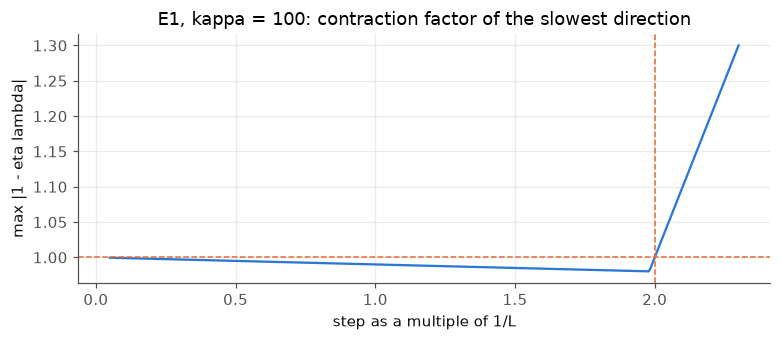

In [3]:
# Figure: the contraction factor of the worst eigen-direction against the step, with the 2/L boundary
cs = np.linspace(0.05, 2.3, 400); rhos = [max(abs(1 - c / L * lam)) for c in cs]
plt.figure(figsize=(7.2, 3.2)); plt.plot(cs, rhos, color=C1); plt.axhline(1, color=C2, lw=1, ls="--"); plt.axvline(2, color=C2, lw=1, ls="--")
plt.xlabel("step as a multiple of 1/L"); plt.ylabel("max |1 - eta lambda|"); plt.title("E1, kappa = 100: contraction factor of the slowest direction"); plt.show()

### §2 — Same loss, zero training error twice, two different models
A $d > n$ least-squares problem: gradient descent from zero reaches the minimum-norm interpolant to fourteen digits; sign descent reaches a different interpolant with a different test error. The method chose the model.

In [4]:
sec(2, "Puzzle 2: same loss, zero training error twice, two different models (d > n least squares)")
n, d = 40, 200
X = rng.standard_normal((n, d))
w_star = np.zeros(d); w_star[:10] = rng.standard_normal(10) * 2   # sparse truth
y = X @ w_star
Xte = rng.standard_normal((2000, d)); yte = Xte @ w_star
def run(update, steps, eta):
    w = np.zeros(d)
    for t in range(steps):
        g = X.T @ (X @ w - y) / n
        w = w - eta * update(g, t)
    return w
w_gd = run(lambda g, t: g, 20000, 0.05)
# sign descent (Adam with beta1 = beta2 = 0, eps -> 0, is sign descent)
w_sign = run(lambda g, t: np.sign(g), 20000, 0.0005)
w_mn = np.linalg.lstsq(X, y, rcond=None)[0]            # minimum-norm interpolant
for name, w in (("GD from 0", w_gd), ("sign descent from 0", w_sign), ("min-norm (pinv)", w_mn)):
    tr = np.mean((X @ w - y) ** 2); te = np.mean((Xte @ w - yte) ** 2)
    print(f"  {name:20s} train MSE = {tr:9.2e}  test MSE = {te:8.4f}  ||w||_2 = {np.linalg.norm(w):7.3f}  ||w||_1 = {np.linalg.norm(w,1):8.2f}  ||w||_inf = {np.abs(w).max():.3f}")
print(f"  ||w_GD - w_minnorm||_2 = {np.linalg.norm(w_gd - w_mn):.2e}   (GD from zero converges to the min-norm interpolant)")


=== §2 Puzzle 2: same loss, zero training error twice, two different models (d > n least squares) ===


  GD from 0            train MSE =  9.15e-32  test MSE =  54.7481  ||w||_2 =   3.336  ||w||_1 =    36.74  ||w||_inf = 0.933
  sign descent from 0  train MSE =  8.58e-05  test MSE =  68.2429  ||w||_2 =   3.867  ||w||_1 =    50.48  ||w||_inf = 0.348
  min-norm (pinv)      train MSE =  4.27e-28  test MSE =  54.7481  ||w||_2 =   3.336  ||w||_1 =    36.74  ||w||_inf = 0.933
  ||w_GD - w_minnorm||_2 = 9.95e-15   (GD from zero converges to the min-norm interpolant)


### §3 — A non-convex problem gradient descent solves from any random start
Rank-one matrix sensing: 100 of 100 random starts reach a global minimiser; a start exactly at the strict saddle $x = 0$ never moves.

In [5]:
sec(3, "Puzzle 3: a non-convex problem that gradient descent solves from any random start (rank-1 matrix sensing)")
# M* = u u^T with u in R^10; m = 200 Gaussian measurements y_i = <A_i, M*>; f(x) = 1/(4m) sum (<A_i, x x^T> - y_i)^2
k, m = 10, 200
u = rng.standard_normal(k); u /= np.linalg.norm(u)
A = rng.standard_normal((m, k, k)); A = (A + A.transpose(0, 2, 1)) / sqrt(2)
yv = np.einsum('mij,i,j->m', A, u, u)
def f_ms(x):
    r = np.einsum('mij,i,j->m', A, x, x) - yv
    return np.sum(r * r) / (4 * m)
def grad_ms(x):
    r = np.einsum('mij,i,j->m', A, x, x) - yv
    return np.einsum('m,mij,j->i', r, A, x) / m
succ = 0; its = []
for trial in range(100):
    x = rng.standard_normal(k) * 0.1
    for t in range(20000):
        x = x - 0.1 * grad_ms(x)
        if f_ms(x) < 1e-12:
            break
    ok = min(np.linalg.norm(x - u), np.linalg.norm(x + u)) < 1e-4
    succ += ok; its.append(t + 1)
print(f"  100 random starts (scale 0.1), step 0.1: reached a global minimiser (x = +/-u to 1e-4) in {succ}/100 runs; steps to f < 1e-12: median {int(np.median(its))}, max {max(its)}")
H0 = -np.einsum('m,mij->ij', yv, A) / m           # Hessian at x = 0 is -(1/m) sum y_i A_i (a strict saddle: negative eigenvalue)
ev = np.linalg.eigvalsh(H0)
print(f"  Hessian at the saddle x = 0: lambda_min = {ev[0]:.4f}, lambda_max = {ev[-1]:.4f}  (lambda_min < 0: x = 0 is a strict saddle, not a minimum)")
x = np.zeros(k)
for t in range(20000):
    x = x - 0.1 * grad_ms(x)
print(f"  started exactly at x = 0: f after 20000 steps = {f_ms(x):.4e}  (gradient descent never leaves a stationary point)")


=== §3 Puzzle 3: a non-convex problem that gradient descent solves from any random start (rank-1 matrix sensing) ===


  100 random starts (scale 0.1), step 0.1: reached a global minimiser (x = +/-u to 1e-4) in 100/100 runs; steps to f < 1e-12: median 84, max 108
  Hessian at the saddle x = 0: lambda_min = -2.5073, lambda_max = 0.5781  (lambda_min < 0: x = 0 is a strict saddle, not a minimum)


  started exactly at x = 0: f after 20000 steps = 6.1520e-01  (gradient descent never leaves a stationary point)


---
## §1 — What convexity buys

### §4 — Convexity is checked on chords
Jensen's inequality as a test: 10,000 random chords per function. The logistic loss passes; $\sin$ and $\sqrt{|x|}$ fail on half of them.

In [6]:
sec(4, "Convexity is checked on chords: Jensen on three functions, 10,000 random chords each")
tests = {"x^2": lambda x: x * x, "exp(x)": np.exp, "log-sum-exp(x, 0)": lambda x: np.logaddexp(x, 0.0), "sin(x)": np.sin, "sqrt|x|": lambda x: np.sqrt(np.abs(x))}
for name, g in tests.items():
    a = rng.uniform(-3, 3, 10000); b = rng.uniform(-3, 3, 10000); th = rng.uniform(0, 1, 10000)
    lhs = g(th * a + (1 - th) * b); rhs = th * g(a) + (1 - th) * g(b)
    viol = np.mean(lhs > rhs + 1e-12)
    print(f"  {name:18s} fraction of chords with f(theta a+(1-theta) b) > theta f(a)+(1-theta) f(b): {viol:.4f}")


=== §4 Convexity is checked on chords: Jensen on three functions, 10,000 random chords each ===
  x^2                fraction of chords with f(theta a+(1-theta) b) > theta f(a)+(1-theta) f(b): 0.0000
  exp(x)             fraction of chords with f(theta a+(1-theta) b) > theta f(a)+(1-theta) f(b): 0.0000
  log-sum-exp(x, 0)  fraction of chords with f(theta a+(1-theta) b) > theta f(a)+(1-theta) f(b): 0.0000
  sin(x)             fraction of chords with f(theta a+(1-theta) b) > theta f(a)+(1-theta) f(b): 0.5034
  sqrt|x|            fraction of chords with f(theta a+(1-theta) b) > theta f(a)+(1-theta) f(b): 0.5586


---
## §2 — Duality, KKT, and the conjugate

### §5 — Weak and strong duality on a soft-margin SVM
Projected gradient ascent on the dual: the dual value is below the primal at every iteration, the two meet to machine precision, and complementary slackness names the support vectors — two of them exactly on the margin.

In [7]:
sec(5, "Weak and strong duality on a bias-free soft-margin SVM: primal and dual objectives meet; KKT names the support vectors")
n, d = 60, 2
Xs = rng.standard_normal((n, d)); ys = np.where(Xs[:, 0] + 0.5 * Xs[:, 1] + 0.3 * rng.standard_normal(n) > 0, 1.0, -1.0)
C = 1.0
Q = (ys[:, None] * Xs) @ (ys[:, None] * Xs).T
# dual: max 1^T a - 1/2 a^T Q a, 0 <= a <= C  (projected gradient ascent)
a = np.zeros(n); step = 1.0 / np.linalg.eigvalsh(Q).max()
def primal(w):
    return 0.5 * w @ w + C * np.sum(np.maximum(0, 1 - ys * (Xs @ w)))
def dual(a):
    return a.sum() - 0.5 * a @ Q @ a
for t in range(1, 20001):
    a = np.clip(a + step * (1 - Q @ a), 0, C)
    if t in (1, 10, 100, 1000, 20000):
        w = (a * ys) @ Xs
        print(f"  iter {t:6d}: dual = {dual(a):.6f}   primal(w(a)) = {primal(w):.6f}   gap = {primal(w)-dual(a):.2e}")
w = (a * ys) @ Xs
marg = ys * (Xs @ w)
print(f"  support vectors (alpha > 1e-6): {np.sum(a > 1e-6)}/{n};  alpha = C (inside margin or misclassified): {np.sum(a > C - 1e-6)};  0 < alpha < C (exactly on the margin, y w.x = 1): {np.sum((a > 1e-6) & (a < C - 1e-6))}")
on = (a > 1e-6) & (a < C - 1e-6)
print(f"  max |y w.x - 1| over the on-margin set = {np.abs(marg[on]-1).max():.2e};  min y w.x over alpha = 0 points = {marg[a<=1e-6].min():.4f} (>= 1: complementary slackness)")


=== §5 Weak and strong duality on a bias-free soft-margin SVM: primal and dual objectives meet; KKT names the support vectors ===
  iter      1: dual = 0.628651   primal(w(a)) = 30.334389   gap = 2.97e+01
  iter     10: dual = 2.875073   primal(w(a)) = 19.140024   gap = 1.63e+01
  iter    100: dual = 12.766033   primal(w(a)) = 13.587708   gap = 8.22e-01
  iter   1000: dual = 13.408400   primal(w(a)) = 13.420371   gap = 1.20e-02


  iter  20000: dual = 13.412993   primal(w(a)) = 13.412993   gap = 3.55e-15
  support vectors (alpha > 1e-6): 17/60;  alpha = C (inside margin or misclassified): 15;  0 < alpha < C (exactly on the margin, y w.x = 1): 2
  max |y w.x - 1| over the on-margin set = 3.89e-15;  min y w.x over alpha = 0 points = 1.0389 (>= 1: complementary slackness)


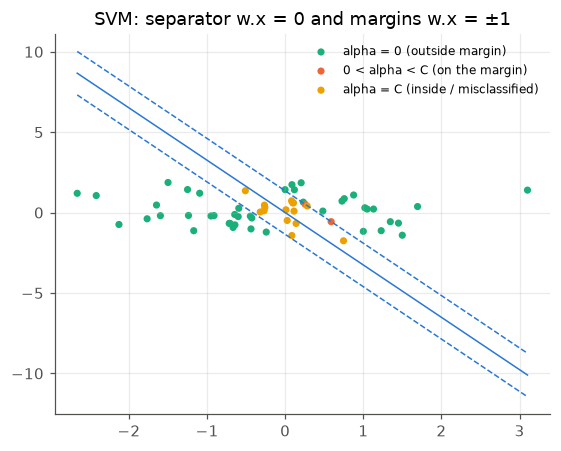

In [8]:
# Figure: the data, the separator, the margins, and the three kinds of point KKT distinguishes
plt.figure(figsize=(5.2, 4.2)); kinds = [(a <= 1e-6, C3, "alpha = 0 (outside margin)"), ((a > 1e-6) & (a < C - 1e-6), C2, "0 < alpha < C (on the margin)"), (a >= C - 1e-6, C4, "alpha = C (inside / misclassified)")]
for mask, col, lab in kinds: plt.scatter(Xs[mask, 0], Xs[mask, 1], c=col, s=22, label=lab, edgecolor="none")
xx = np.linspace(Xs[:, 0].min(), Xs[:, 0].max(), 2)
for off, ls in ((0, "-"), (1, "--"), (-1, "--")): plt.plot(xx, (off - w[0] * xx) / w[1], color=C1, ls=ls, lw=1)
plt.legend(fontsize=8); plt.title("SVM: separator w.x = 0 and margins w.x = ±1"); plt.show()

### §6 — The conjugate of log-sum-exp is negative entropy; the KL-penalised objective has a Gibbs solution
Exponentiated gradient on the simplex finds the softmax as the maximiser of $\langle\theta, p\rangle + H(p)$, and $\pi e^{r/\beta}/Z$ as the maximiser of the KL-penalised reward — the closed form under RLHF and DPO.

In [9]:
sec(6, "Fenchel conjugate of log-sum-exp is negative entropy; the KL-penalised objective has a Gibbs closed form (W41 bridge)")
th = np.array([1.0, 0.0, -1.0, 2.0])
A_th = np.log(np.sum(np.exp(th)))
p_soft = np.exp(th - A_th)
# maximise <theta, p> + H(p) on the simplex by exponentiated gradient (mirror descent with KL)
p = np.ones(4) / 4
for t in range(200):
    g = th - np.log(p) - 1                       # gradient of <theta,p> + H(p)
    p = p * np.exp(0.5 * g); p /= p.sum()
val = th @ p - np.sum(p * np.log(p))
print(f"  A(theta) = log sum exp(theta) = {A_th:.6f};  max_p <theta,p> + H(p) by exponentiated gradient = {val:.6f};  argmax p = {p};  softmax(theta) = {p_soft}")
# RLHF-style: max_p <r,p> - beta KL(p||pi) = beta log E_pi exp(r/beta), argmax = pi exp(r/beta)/Z
r = np.array([2.0, 0.5, -1.0, 1.0]); pi0 = np.array([0.4, 0.3, 0.2, 0.1]); beta = 0.7
p = pi0.copy()
for t in range(400):
    g = r - beta * (np.log(p / pi0) + 1)
    p = p * np.exp(0.3 * g); p /= p.sum()
p_gibbs = pi0 * np.exp(r / beta); Z = p_gibbs.sum(); p_gibbs /= Z
print(f"  KL-penalised argmax by EG = {p}; closed form pi exp(r/beta)/Z = {p_gibbs}; optimal value {r @ p - beta*np.sum(p*np.log(p/pi0)):.6f} vs beta log Z = {beta*log(Z):.6f}")


=== §6 Fenchel conjugate of log-sum-exp is negative entropy; the KL-penalised objective has a Gibbs closed form (W41 bridge) ===
  A(theta) = log sum exp(theta) = 2.440190;  max_p <theta,p> + H(p) by exponentiated gradient = 2.440190;  argmax p = [0.2369 0.0871 0.0321 0.6439];  softmax(theta) = [0.2369 0.0871 0.0321 0.6439]
  KL-penalised argmax by EG = [0.866  0.0762 0.006  0.0519]; closed form pi exp(r/beta)/Z = [0.866  0.0762 0.006  0.0519]; optimal value 1.459336 vs beta log Z = 1.459336


---
## §3 — Rates and lower bounds

### §7 — Gradient descent, heavy ball and Nesterov against their theorems
Iterations to $f - f^\star < 10^{-8}$ on E1 at four condition numbers: $O(\kappa)$ for gradient descent, $O(\sqrt\kappa)$ for the two momentum methods, each below its bound by a constant.

In [10]:
sec(7, "Rates on a quadratic: GD, heavy ball and Nesterov at kappa = 10, 100, 1000, 10,000 — iterations to f - f* < 1e-8, against the theorems' upper bounds")
d = 50
print("  kappa     GD iters   GD bound (1-1/kappa)^2t    HB iters   Nesterov iters   NAG bound (1-1/sqrt kappa)^t")
for kappa in (10, 100, 1000, 10000):
    lam = np.logspace(0, log(kappa, 10), d)       # eigenvalues from 1 to kappa; L = kappa, mu = 1
    L, mu = lam.max(), lam.min()
    x0 = np.ones(d) / sqrt(d)
    f0 = 0.5 * np.sum(lam * x0 * x0)
    def iters(method):
        x = x0.copy(); xp = x0.copy()
        for t in range(1, 400001):
            if method == "GD":
                x = x - (1 / L) * lam * x
            elif method == "HB":                     # Polyak's optimal constants for a quadratic
                a = 4 / (sqrt(L) + sqrt(mu)) ** 2; b = ((sqrt(kappa) - 1) / (sqrt(kappa) + 1)) ** 2
                xn = x - a * lam * x + b * (x - xp); xp, x = x, xn
            else:                                    # Nesterov, strongly convex constants
                yv_ = x + ((sqrt(kappa) - 1) / (sqrt(kappa) + 1)) * (x - xp)
                xn = yv_ - (1 / L) * lam * yv_; xp, x = x, xn
            if 0.5 * np.sum(lam * x * x) < 1e-8:
                return t
        return t
    tg, th_, tn = iters("GD"), iters("HB"), iters("NAG")
    thy_gd = log(1e-8 / f0) / (2 * log(1 - 1 / kappa))          # f contracts by (1-1/kappa)^2 per step (distance by 1-1/kappa)
    thy_nag = log(1e-8 / (2 * f0)) / log(1 - 1 / sqrt(kappa))   # f(x_t)-f* <= (1-1/sqrt kappa)^t (f0-f* + mu/2 ||x0-x*||^2) <= 2 f0 (...)^t here
    print(f"  {kappa:6d}  {tg:9d}  {thy_gd:14.0f}               {th_:8d}   {tn:12d}      {thy_nag:14.0f}")
print("  (a bound is an upper bound: the worst direction holds only 1/d of the initial energy here, so GD beats its bound by a factor ~1.5)")


=== §7 Rates on a quadratic: GD, heavy ball and Nesterov at kappa = 10, 100, 1000, 10,000 — iterations to f - f* < 1e-8, against the theorems' upper bounds ===
  kappa     GD iters   GD bound (1-1/kappa)^2t    HB iters   Nesterov iters   NAG bound (1-1/sqrt kappa)^t
      10         69              91                     18             25                  52
     100        703            1036                     71             88                 204
    1000       6976           11370                    263            291                 730


   10000      69417          123943                    953            935                2536
  (a bound is an upper bound: the worst direction holds only 1/d of the initial energy here, so GD beats its bound by a factor ~1.5)


### §8 — Nesterov's worst-case function
At step $t$ the chain function $f_{2t+1}$ defeats every first-order method: both methods sit above the lower bound, Nesterov's at a constant $3.3\times$ (optimal up to that constant) and gradient descent's ratio growing like $t$.

In [11]:
sec(8, "Nesterov's worst-case function f_{2t+1}: no first-order method beats 3 L ||x0 - x*||^2 / (32 (t+1)^2) at step t, and Nesterov's method is within a constant of it")
L = 1.0
def make(d):
    def f_nest(x):
        return L / 4 * (0.5 * (x[0] ** 2 + np.sum((x[:-1] - x[1:]) ** 2) + x[-1] ** 2) - x[0])
    def g_nest(x):
        g = np.zeros_like(x); dif = x[:-1] - x[1:]
        g[0] += x[0]; g[:-1] += dif; g[1:] -= dif; g[-1] += x[-1]; g[0] -= 1
        return L / 4 * g
    xstar = 1 - np.arange(1, d + 1) / (d + 1)
    return f_nest, g_nest, xstar
print("     t    d=2t+1   GD gap f(x_t)-f*   NAG gap     lower bound 3LR^2/(32(t+1)^2)   GD/bound   NAG/bound   NAG upper bound 4LR^2/(t+2)^2")
for t in (1, 2, 5, 10, 20, 50, 100):
    d = 2 * t + 1
    f_nest, g_nest, xstar = make(d); fstar = f_nest(xstar); R2 = np.sum(xstar ** 2)
    x = np.zeros(d)
    for s in range(t):
        x = x - (1 / L) * g_nest(x)
    gd_gap = f_nest(x) - fstar
    x = np.zeros(d); yk = x.copy(); lam_k = 0.0        # Nesterov's method (Beck–Teboulle / FISTA form), constant step 1/L
    for s in range(t):
        xn = yk - (1 / L) * g_nest(yk); lam_n = (1 + sqrt(1 + 4 * lam_k * lam_k)) / 2
        yk = xn + ((lam_k - 1) / lam_n) * (xn - x); x, lam_k = xn, lam_n
    nag_gap = f_nest(x) - fstar
    lb = 3 * L * R2 / (32 * (t + 1) ** 2); ub = 4 * L * R2 / (t + 2) ** 2
    print(f"  {t:4d}   {d:5d}   {gd_gap:14.6f}   {nag_gap:10.6f}        {lb:12.6f}             {gd_gap/lb:6.2f}      {nag_gap/lb:6.2f}      {ub:12.6f}")
print("  (the function depends on t: at step t the method has only touched coordinates 1..t of a 2t+1-dimensional chain, whatever it did)")


=== §8 Nesterov's worst-case function f_{2t+1}: no first-order method beats 3 L ||x0 - x*||^2 / (32 (t+1)^2) at step t, and Nesterov's method is within a constant of it ===
     t    d=2t+1   GD gap f(x_t)-f*   NAG gap     lower bound 3LR^2/(32(t+1)^2)   GD/bound   NAG/bound   NAG upper bound 4LR^2/(t+2)^2
     1       3         0.046875     0.046875            0.020508               2.29        2.29          0.388889
     2       5         0.040690     0.057292            0.015914               2.56        3.60          0.381944
     5      11         0.031630     0.031762            0.009151               3.46        3.47          0.286848
    10      21         0.024915     0.017577            0.005300               4.70        3.32          0.190025
    20      41         0.018985     0.009321            0.002871               6.61        3.25          0.111603
    50     101         0.012792     0.003915            0.001208              10.59        3.24          0.049559
   100 

### §9 — Subgradient, proximal gradient, FISTA on a lasso
The subgradient method is still at $10^{-3}$ after 2,000 steps; the two proximal methods identify the five-element support and converge exactly by step 100.

In [12]:
sec(9, "Nonsmooth: subgradient O(1/sqrt t) vs proximal gradient O(1/t) vs FISTA O(1/t^2) on a lasso problem")
n, d = 100, 50
Xl = rng.standard_normal((n, d)); wl = np.zeros(d); wl[:5] = (1, -2, 1.5, -1, 0.5)
yl = Xl @ wl + 0.1 * rng.standard_normal(n); lam1 = 0.1
Ll = np.linalg.eigvalsh(Xl.T @ Xl / n).max()
def F(w): return 0.5 * np.mean((Xl @ w - yl) ** 2) + lam1 * np.abs(w).sum()
def gsm(w): return Xl.T @ (Xl @ w - yl) / n
def prox(v, t): return np.sign(v) * np.maximum(np.abs(v) - t, 0)
# reference optimum: 20,000 FISTA iterations
w = np.zeros(d); z = w.copy(); tk = 1.0
for t in range(20000):
    wn = prox(z - gsm(z) / Ll, lam1 / Ll); tn = (1 + sqrt(1 + 4 * tk * tk)) / 2
    z = wn + (tk - 1) / tn * (wn - w); w, tk = wn, tn
Fstar = F(w)
res = {}
w_sg = np.zeros(d); best = np.inf; w_pg = np.zeros(d); w_fi = np.zeros(d); z = w_fi.copy(); tk = 1.0
for t in range(1, 2001):
    w_sg = w_sg - (0.5 / sqrt(t)) * (gsm(w_sg) + lam1 * np.sign(w_sg)); best = min(best, F(w_sg))
    w_pg = prox(w_pg - gsm(w_pg) / Ll, lam1 / Ll)
    wn = prox(z - gsm(z) / Ll, lam1 / Ll); tn = (1 + sqrt(1 + 4 * tk * tk)) / 2
    z = wn + (tk - 1) / tn * (wn - w_fi); w_fi, tk = wn, tn
    if t in (10, 100, 1000, 2000):
        print(f"  t = {t:5d}: subgradient (best) {best-Fstar:10.3e}   proximal {F(w_pg)-Fstar:10.3e}   FISTA {F(w_fi)-Fstar:10.3e}")
print(f"  support of the lasso solution: {np.sum(np.abs(w) > 1e-8)} nonzeros of {d} (truth 5); L = {Ll:.3f}")


=== §9 Nonsmooth: subgradient O(1/sqrt t) vs proximal gradient O(1/t) vs FISTA O(1/t^2) on a lasso problem ===


  t =    10: subgradient (best)  1.031e-01   proximal  1.364e-02   FISTA  1.410e-03
  t =   100: subgradient (best)  9.048e-03   proximal  0.000e+00   FISTA  0.000e+00
  t =  1000: subgradient (best)  2.548e-03   proximal  0.000e+00   FISTA  0.000e+00
  t =  2000: subgradient (best)  1.825e-03   proximal  0.000e+00   FISTA  0.000e+00
  support of the lasso solution: 5 nonzeros of 50 (truth 5); L = 2.923


---
## §4 — Beyond Euclid

### §10 — Mirror descent on the simplex
Exponentiated gradient's step barely depends on $d$ and it finds the best of 100,000 experts; projected gradient with the step its own bound licenses never leaves the uniform point.

In [13]:
sec(10, "Mirror descent on the simplex: exponentiated gradient's log d against projected gradient's sqrt d — the step the theory licenses, d = 10 .. 100,000")
def proj_simplex(v):
    u = np.sort(v)[::-1]; css = np.cumsum(u); rho = np.nonzero(u * np.arange(1, len(v) + 1) > (css - 1))[0][-1]
    th = (css[rho] - 1) / (rho + 1.0); return np.maximum(v - th, 0)
T = 500
print(f"  T = {T} rounds, losses in [0,1]^d, expert 0 better by 0.1 on average. Regret per round, and the mass on expert 0 after T rounds:")
print("      d     EG eta=sqrt(2 ln d/T): regret  p[0]     PGD eta=sqrt(2/(dT)) (its bound's step): regret  p[0]     PGD eta=sqrt(2/T) (untuned): regret  p[0]     bounds: EG sqrt(2 ln d/T)   PGD sqrt(2d/T)")
for dd in (10, 100, 1000, 10000, 100000):
    p_eg = np.ones(dd) / dd; p_pg = np.ones(dd) / dd; p_pg2 = np.ones(dd) / dd
    eta_eg = sqrt(2 * log(dd) / T); eta_pg = sqrt(2 / (dd * T)); eta_pg2 = sqrt(2 / T)
    l_eg = l_pg = l_pg2 = 0.0; cum = np.zeros(dd)
    for t in range(T):
        lvec = rng.uniform(0, 1, dd); lvec[0] = rng.uniform(0, 0.8)
        l_eg += p_eg @ lvec; l_pg += p_pg @ lvec; l_pg2 += p_pg2 @ lvec; cum += lvec
        p_eg = p_eg * np.exp(-eta_eg * lvec); p_eg /= p_eg.sum()
        p_pg = proj_simplex(p_pg - eta_pg * lvec); p_pg2 = proj_simplex(p_pg2 - eta_pg2 * lvec)
    best = cum.min()
    print(f"  {dd:7d}     {(l_eg-best)/T:7.4f}  {p_eg[0]:6.3f}                  {(l_pg-best)/T:7.4f}  {p_pg[0]:6.3f}                               {(l_pg2-best)/T:7.4f}  {p_pg2[0]:6.3f}              {sqrt(2*log(dd)/T):7.4f}            {sqrt(2*dd/T):8.4f}")
print("  (with the step its own bound licenses, projected gradient barely leaves the uniform point once d is large: its guarantee scales with the l2 size of a loss vector, sqrt d; exponentiated gradient's scales with the l_inf size, 1. The untuned PGD step works here because the losses are random, not adversarial)")


=== §10 Mirror descent on the simplex: exponentiated gradient's log d against projected gradient's sqrt d — the step the theory licenses, d = 10 .. 100,000 ===
  T = 500 rounds, losses in [0,1]^d, expert 0 better by 0.1 on average. Regret per round, and the mass on expert 0 after T rounds:
      d     EG eta=sqrt(2 ln d/T): regret  p[0]     PGD eta=sqrt(2/(dT)) (its bound's step): regret  p[0]     PGD eta=sqrt(2/T) (untuned): regret  p[0]     bounds: EG sqrt(2 ln d/T)   PGD sqrt(2d/T)
       10      0.0489   0.930                   0.0508   0.869                                0.0315   0.931               0.0960              0.2000
      100      0.0711   0.931                   0.0949   0.274                                0.1066   0.082               0.1357              0.6325


     1000      0.0856   0.736                   0.0999   0.037                                0.1011   0.000               0.1662              2.0000


    10000      0.0936   0.375                   0.0989   0.000                                0.0979   0.000               0.1919              6.3246


   100000      0.1102   0.539                   0.1176   0.000                                0.1176   0.000               0.2146             20.0000
  (with the step its own bound licenses, projected gradient barely leaves the uniform point once d is large: its guarantee scales with the l2 size of a loss vector, sqrt d; exponentiated gradient's scales with the l_inf size, 1. The untuned PGD step works here because the losses are random, not adversarial)


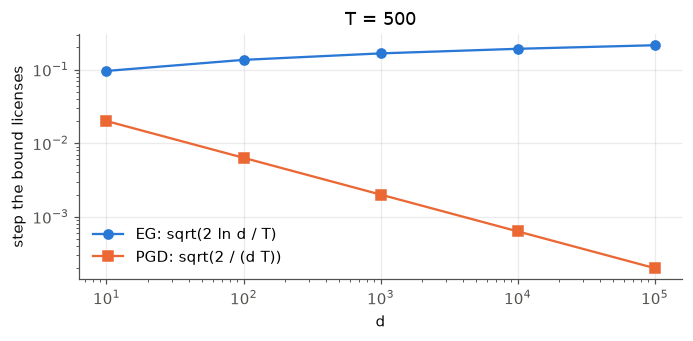

In [14]:
# Figure: the two licensed steps against d
ds = np.array([10, 100, 1000, 10000, 100000]); plt.figure(figsize=(6.4, 3.2))
plt.loglog(ds, np.sqrt(2 * np.log(ds) / T), "o-", color=C1, label="EG: sqrt(2 ln d / T)"); plt.loglog(ds, np.sqrt(2 / (ds * T)), "s-", color=C2, label="PGD: sqrt(2 / (d T))")
plt.xlabel("d"); plt.ylabel("step the bound licenses"); plt.legend(); plt.title("T = 500"); plt.show()

### §11 — Fisher is the Hessian of KL; natural gradient is parametrisation-invariant
Finite differences reproduce the closed-form Fisher in two parametrisations; the natural-gradient step lands at the same distribution either way, the plain gradient step does not.

In [15]:
sec(11, "Fisher information is the Hessian of KL (checked by finite differences), and natural gradient is reparametrisation-invariant")
# Gaussian family N(mu, sigma^2) in two parametrisations: (mu, sigma) and (mu, log sigma)
def kl_gauss(mu1, s1, mu2, s2):
    return log(s2 / s1) + (s1 ** 2 + (mu1 - mu2) ** 2) / (2 * s2 ** 2) - 0.5
mu0, s0 = 0.3, 1.7
h = 1e-3
def hess_kl(param):
    # second derivative of theta -> KL(p_theta0 || p_theta) at theta0 by central differences, in the given parametrisation
    def unpack(th):
        return (th[0], th[1]) if param == "sigma" else (th[0], exp(th[1]))
    th0 = np.array([mu0, s0 if param == "sigma" else log(s0)])
    Hm = np.zeros((2, 2))
    for i in range(2):
        for j in range(2):
            def Kf(di, dj):
                th = th0.copy(); th[i] += di; th[j] += dj; m, s = unpack(th); return kl_gauss(mu0, s0, m, s)
            Hm[i, j] = (Kf(h, h) - Kf(h, -h) - Kf(-h, h) + Kf(-h, -h)) / (4 * h * h)
    return Hm
F_sigma = np.array([[1 / s0 ** 2, 0], [0, 2 / s0 ** 2]]); F_logs = np.array([[1 / s0 ** 2, 0], [0, 2.0]])
print(f"  (mu, sigma):     Hessian of KL = {hess_kl('sigma').ravel()}   Fisher closed form = {F_sigma.ravel()}")
print(f"  (mu, log sigma): Hessian of KL = {hess_kl('logsigma').ravel()}   Fisher closed form = {F_logs.ravel()}")
# one natural-gradient step on the expected negative log-likelihood of data from N(2, 0.5^2), from (mu0, s0), in both parametrisations
mu_d, s_d = 2.0, 0.5
def nll_grad(mu, s, param):      # gradient of E_data[-log p] = log s + (s_d^2 + (mu_d-mu)^2)/(2 s^2) + const
    gmu = -(mu_d - mu) / s ** 2; gs = 1 / s - (s_d ** 2 + (mu_d - mu) ** 2) / s ** 3
    return np.array([gmu, gs]) if param == "sigma" else np.array([gmu, gs * s])
for param in ("sigma", "logsigma"):
    g = nll_grad(mu0, s0, param); Fm = F_sigma if param == "sigma" else F_logs
    step_gd = -0.1 * g; step_ng = -0.1 * np.linalg.solve(Fm, g)
    to_ms = (lambda st: (mu0 + st[0], s0 + st[1])) if param == "sigma" else (lambda st: (mu0 + st[0], exp(log(s0) + st[1])))
    m1, s1 = to_ms(step_gd); m2, s2 = to_ms(step_ng)
    print(f"  {param:9s} plain GD step -> (mu, sigma) = ({m1:.4f}, {s1:.4f});  natural-gradient step -> ({m2:.4f}, {s2:.4f})")


=== §11 Fisher information is the Hessian of KL (checked by finite differences), and natural gradient is reparametrisation-invariant ===
  (mu, sigma):     Hessian of KL = [0.346 0.    0.    0.692]   Fisher closed form = [0.346 0.    0.    0.692]
  (mu, log sigma): Hessian of KL = [0.346 0.    0.    2.   ]   Fisher closed form = [0.346 0.    0.    2.   ]
  sigma     plain GD step -> (mu, sigma) = (0.3588, 1.7051);  natural-gradient step -> (0.4700, 1.7074)
  logsigma  plain GD step -> (mu, sigma) = (0.3588, 1.7148);  natural-gradient step -> (0.4700, 1.7074)


### §12 — Adam's counter-example
Reddi, Kale & Kumar's online losses: Adam drifts to the wrong end of $[-1, 1]$ with linear regret; AMSGrad does not.

In [16]:
sec(12, "Adam's counter-example (Reddi, Kale & Kumar 2018): online linear losses where Adam walks to the wrong end of [-1, 1] and AMSGrad does not")
Cc = 3.0
b1 = 0.0; b2 = 1 / (1 + Cc ** 2); eps = 0.0
def run_adam(ams, T=5000, alpha0=0.1):
    x = 0.0; m_ = 0.0; v = 0.0; vhat = 0.0; regret = 0.0
    for t in range(1, T + 1):
        g = Cc if t % 3 == 1 else -1.0           # f_t(x) = C x on t = 1 mod 3, else -x
        regret += g * x - g * (-1.0 if Cc > 2 else 1.0)   # best fixed point in hindsight: x = -1 (since (C-2)/3 > 0 pushes the sum positive)
        m_ = b1 * m_ + (1 - b1) * g; v = b2 * v + (1 - b2) * g * g
        vhat = max(vhat, v) if ams else v
        x = x - (alpha0 / sqrt(t)) * m_ / (sqrt(vhat) + eps); x = min(1.0, max(-1.0, x))
    return x, regret / T
xa, ra = run_adam(False); xm, rm = run_adam(True)
print(f"  C = {Cc}, beta2 = 1/(1+C^2) = {b2:.3f}: after 5000 rounds Adam sits at x = {xa:+.3f} (average regret {ra:+.4f});  AMSGrad at x = {xm:+.3f} (average regret {rm:+.4f})")
print(f"  the sum of losses over one period of 3 is (C - 2) x = {Cc-2:.1f} x, minimised at x = -1; Adam's step after the C-gradient is small (v just jumped), after each -1 gradient it is large: net drift is toward +1")


=== §12 Adam's counter-example (Reddi, Kale & Kumar 2018): online linear losses where Adam walks to the wrong end of [-1, 1] and AMSGrad does not ===
  C = 3.0, beta2 = 1/(1+C^2) = 0.100: after 5000 rounds Adam sits at x = +1.000 (average regret +0.6536);  AMSGrad at x = -1.000 (average regret +0.0381)
  the sum of losses over one period of 3 is (C - 2) x = 1.0 x, minimised at x = -1; Adam's step after the C-gradient is small (v just jumped), after each -1 gradient it is large: net drift is toward +1


### §13 — Block heterogeneity
Four blocks with curvatures $1, 10, 100, 1000$: one learning rate needs ten thousand steps, one per block needs one.

In [17]:
sec(13, "Block heterogeneity (Zhang et al. 2024 picture): one learning rate for all blocks vs one per block, on a 4-block quadratic")
blocks = [np.full(25, s) for s in (1.0, 10.0, 100.0, 1000.0)]       # four blocks whose curvatures differ by 1000x
lamb = np.concatenate(blocks); L = lamb.max()
x0 = rng.standard_normal(100)
def f_b(x): return 0.5 * np.sum(lamb * x * x)
x = x0.copy()
for t in range(1, 100001):
    x = x - (1 / L) * lamb * x
    if f_b(x) < 1e-8: break
print(f"  GD with the one safe step 1/L (L = {L:.0f}): {t} iterations to f < 1e-8 (the kappa = 1000 block is the bottleneck: f_block1 after t steps = (1-1/1000)^2t f0)")
x = x0.copy()
for t in range(1, 100001):
    x = x - (1 / lamb) * lamb * x                 # per-block step 1/L_block: Newton on a block-diagonal problem
    if f_b(x) < 1e-8: break
print(f"  per-block step 1/L_block: {t} iteration(s)  (each block is a scalar quadratic; a diagonal preconditioner is exact here)")
x = x0.copy(); eta = 0.5; rec = {}
for t in range(1, 201):
    x = x - eta * np.sign(lamb * x); eta *= 0.98
    if t in (10, 50, 100, 200): rec[t] = f_b(x)
print("  sign descent, eta_0 = 0.5 decayed x0.98 per step: f at t = " + ", ".join(f"{t}: {v:.2e}" for t, v in rec.items()) + "   (scale-free in the curvature: the floor is set by the step, 0.5 * 0.98^t, not by kappa)")


=== §13 Block heterogeneity (Zhang et al. 2024 picture): one learning rate for all blocks vs one per block, on a 4-block quadratic ===
  GD with the one safe step 1/L (L = 1000): 10505 iterations to f < 1e-8 (the kappa = 1000 block is the bottleneck: f_block1 after t steps = (1-1/1000)^2t f0)
  per-block step 1/L_block: 1 iteration(s)  (each block is a scalar quadratic; a diagonal preconditioner is exact here)
  sign descent, eta_0 = 0.5 decayed x0.98 per step: f at t = 10: 6.71e+02, 50: 1.70e+02, 100: 2.63e+01, 200: 5.32e-01   (scale-free in the curvature: the floor is set by the step, 0.5 * 0.98^t, not by kappa)


### §14 — Three steepest-descent directions, and Newton–Schulz
Euclidean, $\ell_\infty$ (sign) and spectral ($UV^\top$) directions for one gradient; five Newton–Schulz steps with Muon's coefficients orthonormalise the large singular values and not the one four orders of magnitude down.

In [18]:
sec(14, "Steepest descent under three norms is three updates; Newton–Schulz orthogonalisation (Muon's coefficients) in 5 steps")
G = rng.standard_normal((6, 4)) @ np.diag([3.0, 1.0, 0.3, 0.01]) @ rng.standard_normal((4, 4))
U, S, Vt = np.linalg.svd(G, full_matrices=False)
print(f"  singular values of G: {S}")
print(f"  ||G||_F = {np.linalg.norm(G):.4f}  ||G||_2 = {S[0]:.4f}  ||G||_nuc = {S.sum():.4f}")
d_l2 = G / np.linalg.norm(G); d_linf = np.sign(G) / np.sqrt(G.size); d_spec = U @ Vt   # sign(G)/sqrt(24): Frobenius norm 1 like the Euclidean row (the spectral row U V^T has Frobenius norm sqrt(min(m, n)) = 2), l_inf norm 1/sqrt(24) = 0.204; the l_inf-UNIT direction is sign(G) itself, with <G, sign G> = ||G||_1
for nm, D in (("Euclidean (G/||G||_F)", d_l2), ("l_inf   (sign G, scaled)", d_linf), ("spectral (U V^T)", d_spec)):
    print(f"  {nm:26s} <G, D> = {np.sum(G*D):.4f}   singular values of D: {np.linalg.svd(D, compute_uv=False)}")
# Newton-Schulz with Muon's quintic coefficients, 5 iterations, on G / ||G||_F
a_, b_, c_ = 3.4445, -4.7750, 2.0315
Xn = G / np.linalg.norm(G)
for it in range(1, 6):
    A_ = Xn @ Xn.T; B_ = b_ * A_ + c_ * A_ @ A_
    Xn = a_ * Xn + B_ @ Xn
    print(f"  NS step {it}: singular values -> {np.linalg.svd(Xn, compute_uv=False)}")
# round-3 addendum (no draws): the five-step output is an APPROXIMATION of the polar factor U V^T, whose singular values are all one —
# so Muon's update norms are those of this matrix, not the ideal ||UV^T||_2 = 1 and ||UV^T||_F = sqrt(min(m, n)) = 2 for a 6x4 gradient
sv5 = np.linalg.svd(Xn, compute_uv=False)
print(f"  after 5 steps: ||X||_2 = {sv5[0]:.4f} (exact polar factor: 1), ||X||_F = {np.linalg.norm(Xn):.4f} (exact polar factor: sqrt(min(m, n)) = {sqrt(min(G.shape)):.4f}); the five-step update is {100 * (1 - np.linalg.norm(Xn) / sqrt(min(G.shape))):.1f}% short of the ideal Frobenius norm")
print(f"  the smallest direction ({S[-1]:.4f}; {S[-1]/np.linalg.norm(G):.4f} after Frobenius scaling) is not orthonormalised in 5 steps: NS is a polynomial in the singular values, and small ones lag — the point of the 2026 spectral-scaling-law finding")


=== §14 Steepest descent under three norms is three updates; Newton–Schulz orthogonalisation (Muon's coefficients) in 5 steps ===
  singular values of G: [14.6747  2.3906  0.7442  0.0037]
  ||G||_F = 14.8868  ||G||_2 = 14.6747  ||G||_nuc = 17.8132
  Euclidean (G/||G||_F)      <G, D> = 14.8868   singular values of D: [0.9858 0.1606 0.05   0.0002]
  l_inf   (sign G, scaled)   <G, D> = 10.7062   singular values of D: [0.9391 0.3437 0.     0.    ]
  spectral (U V^T)           <G, D> = 17.8132   singular values of D: [1. 1. 1. 1.]
  NS step 1: singular values -> [0.7125 0.5336 0.1716 0.0009]
  NS step 2: singular values -> [1.2004 1.1001 0.5672 0.0029]
  NS step 3: singular values -> [1.2016 0.9387 0.7053 0.0101]
  NS step 4: singular values -> [1.1087 0.9437 0.7643 0.0349]
  NS step 5: singular values -> [1.0305 0.7581 0.7145 0.12  ]
  after 5 steps: ||X||_2 = 1.0305 (exact polar factor: 1), ||X||_F = 1.4702 (exact polar factor: sqrt(min(m, n)) = 2.0000); the five-step update is 26.5% sho

### §15 — Orthogonalised gradient on an ill-conditioned matrix regression
Each method at its best step from a grid: the orthogonalised update is worse early and an order of magnitude better late. An illustration, labelled as one.

In [19]:
sec(15, "Orthogonalised gradient vs plain gradient on an ill-conditioned matrix regression — each method at its best step from a grid (illustration, not a theorem)")
mdim, ndim, N = 32, 16, 400
Xr = rng.standard_normal((ndim, N)) * np.logspace(0, -2, ndim)[:, None]     # input covariance condition number 1e4
Wt = rng.standard_normal((mdim, ndim)); Yr = Wt @ Xr
L_spec = np.linalg.eigvalsh(Xr @ Xr.T / N).max()
def loss_r(W): return 0.5 * np.mean(np.sum((W @ Xr - Yr) ** 2, 0))
def run_r(kind, mom, eta, T=2000):
    W = np.zeros((mdim, ndim)); M = np.zeros_like(W); hist = {}
    for t in range(1, T + 1):
        Gm = (W @ Xr - Yr) @ Xr.T / N
        M = mom * M + Gm
        if kind == "gd":
            W = W - eta * M
        else:
            Uo, _, Vo = np.linalg.svd(M, full_matrices=False); W = W - eta * (Uo @ Vo) * (0.998 ** t)
        if t in (100, 1000, 2000): hist[t] = loss_r(W)
    return hist
grids = {"gd": [c / L_spec for c in (0.25, 0.5, 1.0, 1.5, 1.9)], "orth": [0.003, 0.01, 0.03, 0.1, 0.3]}
for kind, mom, nm in (("gd", 0.0, "GD"), ("gd", 0.9, "GD + momentum 0.9"), ("orth", 0.0, "orthogonalised (Muon-like), no momentum"), ("orth", 0.9, "orthogonalised + momentum 0.9")):
    best = None
    for eta in grids[kind]:
        h = run_r(kind, mom, eta)
        if best is None or h[2000] < best[1][2000]: best = (eta, h)
    eta, h = best
    print(f"  {nm:42s} best step {eta:8.4f}: " + "  ".join(f"t={t}: {l:9.3e}" for t, l in h.items()))
print(f"  (input condition number 1e4, L = {L_spec:.3f}; the orthogonalised step decays as 0.998^t so that a fixed-length update can settle)")


=== §15 Orthogonalised gradient vs plain gradient on an ill-conditioned matrix regression — each method at its best step from a grid (illustration, not a theorem) ===


  GD                                         best step   1.7442: t=100: 7.946e-02  t=1000: 6.567e-03  t=2000: 2.496e-03


  GD + momentum 0.9                          best step   1.7442: t=100: 7.364e-03  t=1000: 4.667e-05  t=2000: 9.263e-07


  orthogonalised (Muon-like), no momentum    best step   0.0300: t=100: 1.045e+01  t=1000: 4.638e-06  t=2000: 8.474e-08


  orthogonalised + momentum 0.9              best step   0.0300: t=100: 1.045e+01  t=1000: 2.158e-05  t=2000: 4.756e-07
  (input condition number 1e4, L = 1.089; the orthogonalised step decays as 0.998^t so that a fixed-length update can settle)


---
## §5 — The stochastic regime

### §16 — The noise floor
Constant-step SGD on a noisy quadratic is an AR(1) with stationary variance $\alpha\sigma^2/(2-\alpha)$, confirmed at three steps; the $1/t$ schedule is the running mean of the noise.

In [20]:
sec(16, "The noise floor: SGD on a quadratic with additive noise — stationary variance alpha sigma^2 / (2 - alpha), and what decay buys (W43 §8.4 hand-off)")
sig = 1.0
print("  alpha   stationary var (theory)   measured (last 50k of 100k steps)  ± SE")
for alpha in (0.5, 0.1, 0.01):
    x = 0.0; xs = np.empty(100000)
    xi = rng.standard_normal(100000)
    for t in range(100000):
        x = (1 - alpha) * x - alpha * sig * xi[t]; xs[t] = x
    tail = xs[50000:]
    var = np.mean(tail ** 2)
    # SE of a time-average variance of an AR(1): var * sqrt(2 * (1+rho^2)/(1-rho^2) / n), rho = 1-alpha
    rho = 1 - alpha; se = var * sqrt(2 * (1 + rho * rho) / (1 - rho * rho) / len(tail))
    print(f"  {alpha:5.2f}   {alpha*sig**2/(2-alpha):10.5f}               {var:10.5f}                ± {se:.5f}")
# decay: alpha_t = a/t with a*lambda > 1/2 gives O(1/t); here lambda = 1
x = 0.0; xi = rng.standard_normal(100000); rec = {}
for t in range(1, 100001):
    a_t = 1.0 / t
    x = (1 - a_t) * x - a_t * xi[t - 1]
    if t in (100, 1000, 10000, 100000): rec[t] = x * x
print("  alpha_t = 1/t (a lambda = 1 > 1/2): x_t^2 at t = 1e2..1e5 for ONE run: " + ", ".join(f"{t}: {v:.2e}" for t, v in rec.items()) + "   (E x_t^2 = 1/t exactly: the running mean of the noise)")


=== §16 The noise floor: SGD on a quadratic with additive noise — stationary variance alpha sigma^2 / (2 - alpha), and what decay buys (W43 §8.4 hand-off) ===
  alpha   stationary var (theory)   measured (last 50k of 100k steps)  ± SE
   0.50      0.33333                  0.33426                ± 0.00273


   0.10      0.05263                  0.05279                ± 0.00103


   0.01      0.00503                  0.00537                ± 0.00034
  alpha_t = 1/t (a lambda = 1 > 1/2): x_t^2 at t = 1e2..1e5 for ONE run: 100: 2.35e-03, 1000: 2.11e-05, 10000: 2.87e-04, 100000: 4.32e-06   (E x_t^2 = 1/t exactly: the running mean of the noise)


### §17 — The batch-size curve and the gradient noise scale
Steps to a target loss at each batch size, each at its best step, and the fitted $S = S_{\min}(1 + B_{\mathrm{noise}}/B)$. This is the slow cell (a few minutes).

In [21]:
sec(17, "Gradient noise scale and the batch-size curve: steps to a target loss vs batch size on a logistic regression, each batch at its best step, with the fitted S = S_min (1 + B_noise/B)")
n, d = 20000, 30
Xg = rng.standard_normal((n, d)); wg = rng.standard_normal(d) / sqrt(d) * 3
pg = 1 / (1 + np.exp(-(Xg @ wg))); yg = (rng.uniform(size=n) < pg).astype(float)
Xh, yh = Xg[:4000], yg[:4000]                       # the loss is checked on a 4,000-example subset every step
def loss_g(w, X=Xg, y=yg):
    z = X @ w; return np.mean(np.logaddexp(0, z) - y * z)
w_opt = np.zeros(d)
for t in range(3000):
    z = Xg @ w_opt; w_opt -= 0.5 * (Xg.T @ (1 / (1 + np.exp(-z)) - yg) / n)
Lstar = loss_g(w_opt, Xh, yh); L0 = loss_g(np.zeros(d), Xh, yh); target = Lstar + 0.1 * (L0 - Lstar)
z = np.zeros(n); per = Xg * (1 / (1 + np.exp(-z)) - yg)[:, None]
gbar = per.mean(0); Sigma_tr = np.sum(per.var(0)); B_noise0 = Sigma_tr / (gbar @ gbar)
z = Xg @ w_opt; per = Xg * (1 / (1 + np.exp(-z)) - yg)[:, None]
gbar = per.mean(0); B_noise1 = np.sum(per.var(0)) / (gbar @ gbar)
print(f"  gradient noise scale B_noise = tr(Sigma)/||g||^2: {B_noise0:.1f} at w = 0, {B_noise1:.1e} at the optimum (||g|| -> 0: the scale grows along the path)")
print(f"  target = L* + 10% of the initial gap on the 4,000-example check set, checked every step (L* = {Lstar:.4f}, L0 = {L0:.4f})")
print("      B    best eta    steps to target (median of 3)   examples processed")
steps = {}
for B in (1, 4, 16, 64, 256, 1024, 4096):
    best = None
    for eta in (0.02, 0.05, 0.1, 0.2, 0.5, 1.0, 2.0, 4.0):
        runs = []
        for rep in range(3):
            w = np.zeros(d); done = 20000
            for t in range(1, 20001):
                idx = rng.integers(0, n, B); zz = Xg[idx] @ w
                w -= eta * (Xg[idx].T @ (1 / (1 + np.exp(-zz)) - yg[idx]) / B)
                if loss_g(w, Xh, yh) < target: done = t; break
            runs.append(done)
        med = np.median(runs)
        if best is None or med < best[1]: best = (eta, med)
    steps[B] = best[1]
    print(f"  {B:5d}    {best[0]:6.2f}      {int(best[1]):8d}                          {int(best[1]*B):10d}")
Bs = np.array(list(steps), float); Ss = np.array([steps[b] for b in steps], float)
Aa = np.vstack([np.ones_like(Bs), 1 / Bs]).T; coef = np.linalg.lstsq(Aa, Ss, rcond=None)[0]
print(f"  fit S = S_min (1 + B_noise/B): S_min = {coef[0]:.1f} steps, B_noise(fit) = {coef[1]/coef[0]:.1f}")


=== §17 Gradient noise scale and the batch-size curve: steps to a target loss vs batch size on a logistic regression, each batch at its best step, with the fitted S = S_min (1 + B_noise/B) ===


  gradient noise scale B_noise = tr(Sigma)/||g||^2: 76.5 at w = 0, 3.7e+31 at the optimum (||g|| -> 0: the scale grows along the path)
  target = L* + 10% of the initial gap on the 4,000-example check set, checked every step (L* = 0.4332, L0 = 0.6931)
      B    best eta    steps to target (median of 3)   examples processed


      1      0.02           665                                 665


      4      0.10           197                                 788


     16      0.50            46                                 736


     64      1.00            15                                 960


    256      4.00             4                                1024


   1024      4.00             2                                2048


   4096      4.00             2                                8192
  fit S = S_min (1 + B_noise/B): S_min = 6.4 steps, B_noise(fit) = 103.2


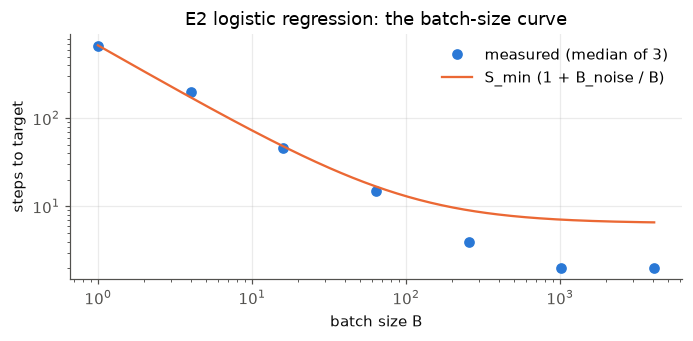

In [22]:
# Figure: measured steps against batch size with the fitted curve
Bf = np.logspace(0, np.log10(4096), 200); plt.figure(figsize=(6.4, 3.2))
plt.loglog(Bs, Ss, "o", color=C1, label="measured (median of 3)"); plt.loglog(Bf, coef[0] * (1 + (coef[1] / coef[0]) / Bf), color=C2, label="S_min (1 + B_noise / B)")
plt.xlabel("batch size B"); plt.ylabel("steps to target"); plt.legend(); plt.title("E2 logistic regression: the batch-size curve"); plt.show()

### §18 — Variance reduction
SVRG at a constant step reaches machine precision by epoch 20 on a finite-sum problem where constant-step SGD sits on its floor.

In [23]:
sec(18, "Variance reduction: SVRG's linear rate against SGD's noise floor on a finite-sum strongly convex logistic regression")
n, d = 1000, 20
Xv = rng.standard_normal((n, d)); wv = rng.standard_normal(d); yv2 = np.where(Xv @ wv + 0.5 * rng.standard_normal(n) > 0, 1.0, 0.0)
lam2 = 1e-2
def Fv(w): z = Xv @ w; return np.mean(np.logaddexp(0, z) - yv2 * z) + lam2 / 2 * w @ w
def gv(w, idx): z = Xv[idx] @ w; return Xv[idx].T @ (1 / (1 + np.exp(-z)) - yv2[idx]) / len(idx) + lam2 * w
w = np.zeros(d)
for t in range(5000): w -= 0.5 * gv(w, np.arange(n))
Fst = Fv(w)
w_sgd = np.zeros(d); w_svrg = np.zeros(d); eta = 0.1
print("  epochs   SGD (eta=0.1/sqrt(epoch))   SGD (eta=0.1)    SVRG (eta=0.1)")
w_sgdd = np.zeros(d)
for ep in range(1, 31):
    for i in range(n):
        idx = rng.integers(0, n, 1)
        w_sgd -= eta * gv(w_sgd, idx)
        w_sgdd -= (eta / sqrt(ep)) * gv(w_sgdd, idx)
    # SVRG epoch: full gradient at snapshot, then n corrected steps
    snap = w_svrg.copy(); gfull = gv(snap, np.arange(n))
    for i in range(n):
        idx = rng.integers(0, n, 1)
        w_svrg -= eta * (gv(w_svrg, idx) - gv(snap, idx) + gfull)
    if ep in (1, 2, 5, 10, 20, 30):
        print(f"  {ep:5d}     {Fv(w_sgdd)-Fst:12.3e}             {Fv(w_sgd)-Fst:12.3e}     {Fv(w_svrg)-Fst:12.3e}")


=== §18 Variance reduction: SVRG's linear rate against SGD's noise floor on a finite-sum strongly convex logistic regression ===


  epochs   SGD (eta=0.1/sqrt(epoch))   SGD (eta=0.1)    SVRG (eta=0.1)
      1        3.311e-02                3.311e-02        1.207e-01


      2        1.441e-02                2.228e-02        1.196e-02


      5        8.107e-03                2.867e-02        1.140e-04


     10        5.579e-03                2.331e-02        1.372e-08


     20        5.870e-03                2.437e-02        5.274e-16


     30        5.940e-03                3.126e-02        0.000e+00


### §19 — Schedules on the noisy quadratic model
Expected loss computed exactly for constant, cosine, WSD and $1/\sqrt t$ schedules; the cooldown collapses the noise floor, and tail averaging does the same without changing the step.

In [24]:
sec(19, "Schedules on the noisy quadratic model (exact expectations, no sampling): constant, cosine, WSD, 1/sqrt t — and tail averaging, simulated")
# NQM: f(x) = 1/2 sum h_i x_i^2, gradient noise variance h_i * c / B per coordinate (Zhang et al. 2019). Per-coordinate recursions for E x_i^2 are exact.
dq = 1000; hq = 1.0 / np.arange(1, dq + 1); cq = 1.0; Bq = 64
Tq = 2000; eta_max = 1.0 / hq.max()
def nqm_loss(sched):
    m2 = np.ones(dq)            # E x_i^2 at t = 0 (x_0 = 1 in every coordinate)
    loss = []
    for t in range(Tq):
        eta = sched(t)
        m2 = (1 - eta * hq) ** 2 * m2 + eta ** 2 * hq * cq / Bq
        loss.append(0.5 * np.sum(hq * m2))
    return np.array(loss)
scheds = {
    "constant eta_max": lambda t: eta_max,
    "cosine to 0": lambda t: eta_max * 0.5 * (1 + math.cos(pi * t / Tq)),
    "WSD (80% const, 20% linear cooldown)": lambda t: eta_max if t < 0.8 * Tq else eta_max * (Tq - t) / (0.2 * Tq),
    "1/sqrt(t)": lambda t: eta_max / sqrt(1 + t / 50),
    "constant eta_max/10": lambda t: eta_max / 10,
}
print(f"  d = {dq}, h_i = 1/i, noise c/B = {cq/Bq}, T = {Tq}; expected loss at t = 400, 1600, 2000:")
for nm, s in scheds.items():
    lo = nqm_loss(s)
    print(f"  {nm:38s} {lo[399]:9.5f}   {lo[1599]:9.5f}   {lo[-1]:9.5f}")
last, tail = [], []
for rep in range(20):
    xs = np.ones(dq); avg = np.zeros(dq); eta = eta_max; cnt = 0
    noise = rng.standard_normal((Tq, dq))
    for t in range(Tq):
        xs = xs - eta * (hq * xs + np.sqrt(hq * cq / Bq) * noise[t])
        if t >= 0.75 * Tq: cnt += 1; avg += (xs - avg) / cnt
    last.append(0.5 * np.sum(hq * xs * xs)); tail.append(0.5 * np.sum(hq * avg * avg))
print(f"  constant eta_max, 20 simulated runs: last-iterate loss {np.mean(last):.5f} ± {se_mean(last):.5f}, loss of the average over the last 25% {np.mean(tail):.5f} ± {se_mean(tail):.5f}  (averaging buys most of what the cooldown buys)")


=== §19 Schedules on the noisy quadratic model (exact expectations, no sampling): constant, cosine, WSD, 1/sqrt t — and tail averaging, simulated ===
  d = 1000, h_i = 1/i, noise c/B = 0.015625, T = 2000; expected loss at t = 400, 1600, 2000:
  constant eta_max                         0.18860     0.03968     0.03653
  cosine to 0                              0.19244     0.03174     0.02911
  WSD (80% const, 20% linear cooldown)     0.18860     0.03968     0.01245


  1/sqrt(t)                                0.36087     0.12515     0.10100
  constant eta_max/10                      1.01556     0.43190     0.35398


  constant eta_max, 20 simulated runs: last-iterate loss 0.03473 ± 0.00298, loss of the average over the last 25% 0.01064 ± 0.00011  (averaging buys most of what the cooldown buys)


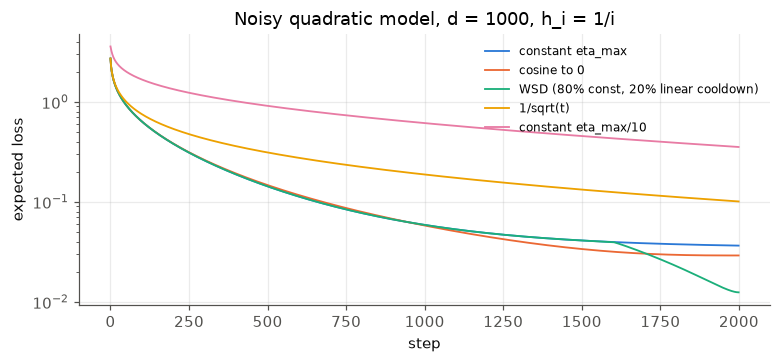

In [25]:
# Figure: the expected loss curves of the five schedules
plt.figure(figsize=(7.2, 3.4))
for (nm, s), col in zip(scheds.items(), (C1, C2, C3, C4, C5)): plt.semilogy(nqm_loss(s), color=col, label=nm, lw=1.2)
plt.xlabel("step"); plt.ylabel("expected loss"); plt.legend(fontsize=8); plt.title("Noisy quadratic model, d = 1000, h_i = 1/i"); plt.show()

### §20 — Adam's first step is a sign step
The bias corrections cancel at $t = 1$ and the update has Euclidean length $\eta\sqrt d$ whatever the gradient — the oldest reason for warmup.

In [26]:
sec(20, "Adam's first step is a sign step: ||x_1 - x_0||_2 = eta sqrt(d) regardless of the gradient — why warmup exists")
for dd in (10, 10 ** 4, 10 ** 6):
    g = rng.standard_normal(dd) * 1e-3           # tiny gradients
    m_ = 0.1 * g; v = 0.001 * g * g               # beta1 = 0.9, beta2 = 0.999, t = 1
    mhat = m_ / 0.1; vhat = v / 0.001
    upd = mhat / (np.sqrt(vhat) + 1e-8)
    print(f"  d = {dd:8d}: ||update||_2 / eta = {np.linalg.norm(upd):10.2f}   sqrt(d) = {sqrt(dd):10.2f}   (||g||_2 was {np.linalg.norm(g):.4f})")
print("  draws: three Gaussian vectors; the identity is exact up to eps")


=== §20 Adam's first step is a sign step: ||x_1 - x_0||_2 = eta sqrt(d) regardless of the gradient — why warmup exists ===
  d =       10: ||update||_2 / eta =       3.16   sqrt(d) =       3.16   (||g||_2 was 0.0040)
  d =    10000: ||update||_2 / eta =      99.99   sqrt(d) =     100.00   (||g||_2 was 0.1007)
  d =  1000000: ||update||_2 / eta =     999.91   sqrt(d) =    1000.00   (||g||_2 was 0.9980)
  draws: three Gaussian vectors; the identity is exact up to eps


### §21 — Weight decay sets an equilibrium norm
Under AdamW-style updates the per-coordinate norm converges to $\sqrt{\eta/2\lambda}$ and the angular step to $\sqrt{2\eta\lambda}$, on the timescale $1/(\eta\lambda)$.

In [27]:
sec(21, "Weight decay sets an equilibrium norm, not a penalty: ||w|| under AdamW-style updates converges to sqrt(eta / (2 lambda)) per coordinate, and the angular step to sqrt(2 eta lambda)")
dd = 1000; eta = 1e-2; lam_wd = 0.1
w = rng.standard_normal(dd) * 3
print("  (random unit-RMS update directions, uncorrelated with w: the W43 AR(1) with a different name; timescale 1/(eta lambda) = 1000 steps)")
for t in range(1, 20001):
    u = rng.standard_normal(dd)                   # Adam-like update with RMS 1 per coordinate
    w_new = w - eta * (u + lam_wd * w)
    if t in (1, 100, 1000, 3000, 10000, 20000):
        ang = math.acos(min(1.0, (w @ w_new) / (np.linalg.norm(w) * np.linalg.norm(w_new))))
        print(f"  t = {t:6d}: ||w||_2 / sqrt(d) = {np.linalg.norm(w_new)/sqrt(dd):.4f}   equilibrium sqrt(eta/(2 lambda)) = {sqrt(eta/(2*lam_wd)):.4f}   angular step this update = {ang:.4f} rad   equilibrium sqrt(2 eta lambda) = {sqrt(2*eta*lam_wd):.4f}")
    w = w_new


=== §21 Weight decay sets an equilibrium norm, not a penalty: ||w|| under AdamW-style updates converges to sqrt(eta / (2 lambda)) per coordinate, and the angular step to sqrt(2 eta lambda) ===
  (random unit-RMS update directions, uncorrelated with w: the W43 AR(1) with a different name; timescale 1/(eta lambda) = 1000 steps)
  t =      1: ||w||_2 / sqrt(d) = 3.0832   equilibrium sqrt(eta/(2 lambda)) = 0.2236   angular step this update = 0.0033 rad   equilibrium sqrt(2 eta lambda) = 0.0447
  t =    100: ||w||_2 / sqrt(d) = 2.7932   equilibrium sqrt(eta/(2 lambda)) = 0.2236   angular step this update = 0.0035 rad   equilibrium sqrt(2 eta lambda) = 0.0447
  t =   1000: ||w||_2 / sqrt(d) = 1.1573   equilibrium sqrt(eta/(2 lambda)) = 0.2236   angular step this update = 0.0084 rad   equilibrium sqrt(2 eta lambda) = 0.0447
  t =   3000: ||w||_2 / sqrt(d) = 0.2677   equilibrium sqrt(eta/(2 lambda)) = 0.2236   angular step this update = 0.0356 rad   equilibrium sqrt(2 eta lambda) = 0.0447


  t =  10000: ||w||_2 / sqrt(d) = 0.2235   equilibrium sqrt(eta/(2 lambda)) = 0.2236   angular step this update = 0.0455 rad   equilibrium sqrt(2 eta lambda) = 0.0447


  t =  20000: ||w||_2 / sqrt(d) = 0.2167   equilibrium sqrt(eta/(2 lambda)) = 0.2236   angular step this update = 0.0461 rad   equilibrium sqrt(2 eta lambda) = 0.0447


### §40 — Three errors in one excess risk (article §5.7)
On the Probability Domain's E2: the estimation term falls with $n$, the one-pass optimisation term does not, and at small $n$ the under-optimised model is the better one.

In [28]:
sec(40, "Three optimisation errors in one excess risk (Bottou & Bousquet 2008): approximation, estimation and optimisation, measured on E2 of the Probability Domain")
# E2: two-class Gaussian mixture in d = 20, means +/- mu e1 with mu = 1, identity covariance; Bayes risk Phi(-1) = 0.1587
d = 20; mu_e = 1.0
def sample_e2(n):
    y = np.where(rng.uniform(size=n) < 0.5, 1.0, -1.0); X = rng.standard_normal((n, d)); X[:, 0] += mu_e * y; return X, y
Xte, yte = sample_e2(200000)
def err(w): return np.mean(np.sign(Xte @ w) != yte)
bayes = Phi(-mu_e)
w_bayes = np.zeros(d); w_bayes[0] = 1.0
print(f"  Bayes risk Phi(-1) = {bayes:.4f}; the Bayes classifier is in the linear class: approximation error = 0 here by construction")
print("      n     exact empirical minimiser (full GD): excess risk     one-pass SGD (eta=0.05): excess risk — a TOTAL, not an added term")
for n in (100, 1000, 10000):
    Xn, yn = sample_e2(n)
    w = np.zeros(d)
    for t in range(2000): z = yn * (Xn @ w); w += 0.5 * (Xn * (yn / (1 + np.exp(z)))[:, None]).mean(0)
    e_full = err(w)
    ws = np.zeros(d)
    for i in range(n): z = yn[i] * (Xn[i] @ ws); ws += 0.05 * Xn[i] * yn[i] / (1 + exp(z))
    e_sgd = err(ws)
    print(f"  {n:6d}     {e_full-bayes:10.4f}                                       {e_sgd-bayes:10.4f}")
print("  (the left column is the estimation term; the right column is the one-pass model's whole excess risk, which can be BELOW the left one — under-optimising is a regulariser at small n; past a point, more passes buy less than more data — the argument for SGD at scale)")


=== §40 Three optimisation errors in one excess risk (Bottou & Bousquet 2008): approximation, estimation and optimisation, measured on E2 of the Probability Domain ===
  Bayes risk Phi(-1) = 0.1587; the Bayes classifier is in the linear class: approximation error = 0 here by construction
      n     exact empirical minimiser (full GD): excess risk     one-pass SGD (eta=0.05): excess risk — a TOTAL, not an added term
     100         0.0795                                           0.0323


    1000         0.0051                                           0.0144


   10000         0.0005                                           0.0143
  (the left column is the estimation term; the right column is the one-pass model's whole excess risk, which can be BELOW the left one — under-optimising is a regulariser at small n; past a point, more passes buy less than more data — the argument for SGD at scale)


---
## Critic round 1 addenda (2026-10-30) — the counter-examples, computed

### §47 — Checkpoint exercise 2 (article §1.5): the same contraction factor, losses $63\times$ apart
At $1/L$ the slowest direction ($\lambda = \mu = 1$) contracts by $0.99$; at $1.99/L$ the stiffest ($\lambda = L = 100$) oscillates with the same factor $0.99$. The amplitude decays identically; the loss weights it by the curvature, a factor of 100.

In [29]:
sec(47, "Checkpoint 2: 1.99/L and 1/L have the SAME contraction factor 0.99 on E1 and losses 63x apart — the oscillating direction carries curvature L, the slow one carries curvature mu")
lam47 = np.logspace(0, 2, 20); L47 = lam47.max()
for c in (1.0, 1.99):
    eta = c / L47; fac = 1 - eta * lam47; x = fac ** 200                                      # x_200 per eigen-direction from x_0 = 1
    f_dir = 0.5 * lam47 * x * x; worst = int(np.argmax(np.abs(fac)))
    print(f"  eta = {c:4.2f}/L: max|1 - eta lambda| = {np.abs(fac).max():.4f} at lambda = {lam47[worst]:6.2f}; that direction's share of f(x_200) = {f_dir[worst]:.4e} = (1/2) lambda 0.99^400; total f(x_200) = {f_dir.sum():.4e}")
ratio47 = (0.5 * lam47 * (1 - 1.99 / L47 * lam47) ** 400).sum() / (0.5 * lam47 * (1 - 1 / L47 * lam47) ** 400).sum()
print(f"  ratio f_200(1.99/L) / f_200(1/L) = {ratio47:.1f}: the same amplitude decay 0.99^200 in the worst direction, weighted by a curvature 100x larger (less what the other directions still hold at 1/L)")


=== §47 Checkpoint 2: 1.99/L and 1/L have the SAME contraction factor 0.99 on E1 and losses 63x apart — the oscillating direction carries curvature L, the slow one carries curvature mu ===
  eta = 1.00/L: max|1 - eta lambda| = 0.9900 at lambda =   1.00; that direction's share of f(x_200) = 8.9753e-03 = (1/2) lambda 0.99^400; total f(x_200) = 1.4182e-02
  eta = 1.99/L: max|1 - eta lambda| = 0.9900 at lambda = 100.00; that direction's share of f(x_200) = 8.9753e-01 = (1/2) lambda 0.99^400; total f(x_200) = 8.9771e-01
  ratio f_200(1.99/L) / f_200(1/L) = 63.3: the same amplitude decay 0.99^200 in the worst direction, weighted by a curvature 100x larger (less what the other directions still hold at 1/L)


### §42 — Heavy ball's prefactor (article §3.3)
At $\lambda = \mu$ and $\lambda = L$ the companion matrix has a double root, so the iterate is $(1 + ct)\,q^t x_0$: the rate $q = (\sqrt\kappa - 1)/(\sqrt\kappa + 1)$ is right and no $T$-independent constant sits in front of it.

In [30]:
sec(42, "Heavy ball's rate has a prefactor that grows with T: at the extreme eigenvalues the companion matrix has a double root, so x_T = (1 + c T) q^T x_0, not C q^T x_0")
# Polyak's constants on a quadratic with eigenvalues in [mu, L]: alpha = 4/(sqrt L + sqrt mu)^2, beta = ((sqrt k - 1)/(sqrt k + 1))^2 = q^2.
# Along an eigen-direction of curvature lam the iteration is x_{t+1} = (1 + beta - alpha lam) x_t - beta x_{t-1}; its two characteristic roots have
# modulus sqrt(beta) = q for every lam in [mu, L] (that is the sqrt(kappa) rate), and at lam = mu and lam = L they COINCIDE (double root +q, resp. -q),
# so the solution there is (A + B t) q^t: a prefactor linear in t. With x_{-1} = x_0 (zero initial momentum): x_t = (1 + (1 - q) t) q^t x_0 at lam = mu
# and x_t = (1 + (1 + q) t) (-q)^t x_0 at lam = L. No T-independent C satisfies ||x_T|| <= C q^T ||x_0||; the correct statements carry a polynomial
# prefactor, or read C_delta (q + delta)^T for any delta > 0 — and the O(sqrt(kappa) log(1/eps)) iteration count survives both.
kappa_hb = 100.0; L_hb, mu_hb = kappa_hb, 1.0
alpha_hb = 4 / (sqrt(L_hb) + sqrt(mu_hb)) ** 2; q_hb = (sqrt(kappa_hb) - 1) / (sqrt(kappa_hb) + 1); beta_hb = q_hb ** 2
def hb_ratio(lam_, T_):
    x_prev, x_cur = 1.0, 1.0
    for _ in range(T_):
        x_prev, x_cur = x_cur, (1 + beta_hb - alpha_hb * lam_) * x_cur - beta_hb * x_prev
    return abs(x_cur)
print(f"  kappa = {kappa_hb:.0f}: alpha = {alpha_hb:.5f}, beta = q^2 = {beta_hb:.5f}, q = {q_hb:.5f}; double root +q at lam = mu, -q at lam = L; x_{{-1}} = x_0")
print("      T    |x_T|/|x_0| at lam = mu    (1 + (1-q) T) q^T    at lam = L     (1 + (1+q) T) q^T    max over 2001 lam in [mu, L]     q^T alone")
lams_hb = np.linspace(mu_hb, L_hb, 2001)
for T_ in (10, 100, 1000):
    r_mu = hb_ratio(mu_hb, T_); r_L = hb_ratio(L_hb, T_); r_max = max(hb_ratio(l_, T_) for l_ in lams_hb)
    print(f"  {T_:5d}      {r_mu:11.4e}          {(1 + (1 - q_hb) * T_) * q_hb ** T_:11.4e}      {r_L:11.4e}     {(1 + (1 + q_hb) * T_) * q_hb ** T_:11.4e}         {r_max:11.4e}          {q_hb ** T_:11.4e}")
print(f"  (the prefactor at T = 100 is {1 + (1 - q_hb) * 100:.1f} at the soft end and {1 + (1 + q_hb) * 100:.1f} at the stiff end, and both grow without bound: the rate q^T is right, the 'constant' in front of it is not a constant)")


=== §42 Heavy ball's rate has a prefactor that grows with T: at the extreme eigenvalues the companion matrix has a double root, so x_T = (1 + c T) q^T x_0, not C q^T x_0 ===
  kappa = 100: alpha = 0.03306, beta = q^2 = 0.66942, q = 0.81818; double root +q at lam = mu, -q at lam = L; x_{-1} = x_0
      T    |x_T|/|x_0| at lam = mu    (1 + (1-q) T) q^T    at lam = L     (1 + (1+q) T) q^T    max over 2001 lam in [mu, L]     q^T alone
     10       3.7885e-01           3.7885e-01       2.5786e+00      2.5786e+00          2.5786e+00           1.3443e-01
    100       3.6972e-08           3.6972e-08       3.5237e-07      3.5237e-07          3.5237e-07           1.9274e-09


   1000       1.2937e-85           1.2937e-85       1.2874e-84      1.2874e-84          1.2874e-84           7.0766e-88
  (the prefactor at T = 100 is 19.2 at the soft end and 182.8 at the stiff end, and both grow without bound: the rate q^T is right, the 'constant' in front of it is not a constant)


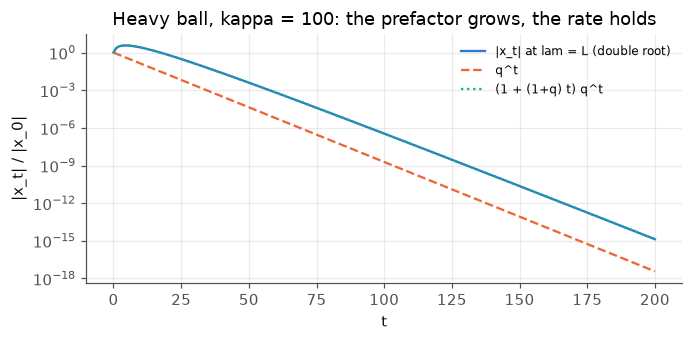

In [31]:
# Figure: |x_t|/|x_0| along the stiffest eigen-direction against q^t — the polynomial prefactor
ts_ = np.arange(0, 201); traj_ = [hb_ratio(L_hb, int(t)) for t in ts_]
plt.figure(figsize=(6.4, 3.2)); plt.semilogy(ts_, traj_, color=C1, label="|x_t| at lam = L (double root)"); plt.semilogy(ts_, q_hb ** ts_, color=C2, ls="--", label="q^t"); plt.semilogy(ts_, (1 + (1 + q_hb) * ts_) * q_hb ** ts_, color=C3, ls=":", label="(1 + (1+q) t) q^t")
plt.xlabel("t"); plt.ylabel("|x_t| / |x_0|"); plt.legend(fontsize=8); plt.title("Heavy ball, kappa = 100: the prefactor grows, the rate holds"); plt.show()

### §46 — Adam's step is not capped at $\eta$ (article §4.4)
After a long quiet stretch a single gradient moves a coordinate by up to $\eta(1-\beta_1)/\sqrt{1-\beta_2} = 3.16\eta$: the trust-region reading is an intuition about stationary gradients, not a bound.

In [32]:
sec(46, "Adam's per-coordinate step is not capped at eta: after a long quiet stretch one gradient moves a coordinate by up to eta (1 - beta1)/sqrt(1 - beta2) = 3.16 eta")
# m_t = b1 m + (1-b1) g, v_t = b2 v + (1-b2) g^2, both bias-corrected; step = eta m_hat / sqrt(v_hat). The 'trust region of radius eta' reading holds while
# g is CONSTANT (then m_hat = g, sqrt(v_hat) = |g|, step = eta); a Jensen bound |m_hat| <= sqrt(v_hat) would need both averages to carry the same
# weights, and with b1 != b2 they do not (§48 is the supremum that gap allows). It fails outright when a large gradient arrives after many near-zero ones:
# m is then (1-b1) g and v is (1-b2) g^2, so the ratio is (1-b1)/sqrt(1-b2) once the bias corrections have decayed (Kingma & Ba 2015, §2.1).
b1_a, b2_a = 0.9, 0.999
print("      t0 (quiet steps, then one unit gradient)     |step| / eta at t0     bound (1-b1)/sqrt(1-b2)")
for t0_ in (1, 10, 100, 1000, 10000):
    m_a = v_a = 0.0
    for t_ in range(1, t0_ + 1):
        g_ = 1.0 if t_ == t0_ else 0.0
        m_a = b1_a * m_a + (1 - b1_a) * g_; v_a = b2_a * v_a + (1 - b2_a) * g_ * g_
    mhat = m_a / (1 - b1_a ** t0_); vhat = v_a / (1 - b2_a ** t0_)
    print(f"  {t0_:10d}                                         {abs(mhat)/sqrt(vhat):8.4f}                {(1-b1_a)/sqrt(1-b2_a):8.4f}")
print("  (at t0 = 1 the step is the sign step of §20; it falls below eta while v's bias correction is still large and climbs to the 3.16 eta cap as the quiet stretch outlives 1/(1 - beta2): eta bounds the step only up to this factor, and only through v's memory)")


=== §46 Adam's per-coordinate step is not capped at eta: after a long quiet stretch one gradient moves a coordinate by up to eta (1 - beta1)/sqrt(1 - beta2) = 3.16 eta ===
      t0 (quiet steps, then one unit gradient)     |step| / eta at t0     bound (1-b1)/sqrt(1-b2)
           1                                           1.0000                  3.1623
          10                                           0.4844                  3.1623
         100                                           0.9758                  3.1623
        1000                                           2.5146                  3.1623
       10000                                           3.1622                  3.1623
  (at t0 = 1 the step is the sign step of §20; it falls below eta while v's bias correction is still large and climbs to the 3.16 eta cap as the quiet stretch outlives 1/(1 - beta2): eta bounds the step only up to this factor, and only through v's memory)


### §43 — The KL-penalised objective is concave in $p$, not in the logits (article §1.5, §2.4, §9.2)
Two actions, zero reward, uniform reference: $J(z) = -\mathrm{KL}(\mathrm{Ber}(\sigma(z))\,\|\,\mathrm{Ber}(1/2))$ has $J''(2) = +0.0549$.

In [33]:
sec(43, "The KL-penalised objective is concave in the policy's probabilities and NOT in its logits: a two-action counter-example")
# max_p <r, p> - beta KL(p || pi_ref) is concave on the simplex (Identity 2, §6). Parametrise a two-action policy by one logit z, p = sigmoid(z); take
# r = 0, pi_ref uniform, beta = 1: J(z) = -KL(Ber(p(z)) || Ber(1/2)) = H(p(z)) - log 2.  dJ/dz = -z p (1 - p);  d2J/dz2 = -p (1 - p) [1 + z (1 - 2p)].
# Concavity in z needs d2J/dz2 <= 0 everywhere; at z = 2 it is positive.
def J_logit(z): p = 1 / (1 + exp(-z)); return -(p * log(2 * p) + (1 - p) * log(2 * (1 - p)))
def J2_closed(z): p = 1 / (1 + exp(-z)); return -p * (1 - p) * (1 + z * (1 - 2 * p))
print("      z     J(z) = -KL(Ber(sigmoid z) || Ber(1/2))     J''(z) closed form     J''(z) by central differences (h = 1e-4)")
for z_ in (0.0, 1.0, 1.5, 2.0, 3.0):
    h_ = 1e-4; fd_ = (J_logit(z_ + h_) - 2 * J_logit(z_) + J_logit(z_ - h_)) / h_ ** 2
    print(f"  {z_:5.1f}     {J_logit(z_):12.6f}                                {J2_closed(z_):+10.5f}             {fd_:+10.5f}")
print("  (J'' > 0 at z = 2 and z = 3: the objective is not concave in the logit although it is strictly concave in p; the sign flips once z (2p - 1) > 1, i.e. once the policy is confident — the sigmoid's own curvature overwhelms the KL's)")


=== §43 The KL-penalised objective is concave in the policy's probabilities and NOT in its logits: a two-action counter-example ===
      z     J(z) = -KL(Ber(sigmoid z) || Ber(1/2))     J''(z) closed form     J''(z) by central differences (h = 1e-4)
    0.0        -0.000000                                  -0.25000               -0.25000
    1.0        -0.110944                                  -0.10575               -0.10575
    1.5        -0.218096                                  -0.00705               -0.00705
    2.0        -0.327813                                  +0.05493               +0.05493
    3.0        -0.502282                                  +0.07750               +0.07750
  (J'' > 0 at z = 2 and z = 3: the objective is not concave in the logit although it is strictly concave in p; the sign flips once z (2p - 1) > 1, i.e. once the policy is confident — the sigmoid's own curvature overwhelms the KL's)


---
## Critic round 2 addenda (2026-10-30)

### §48 — Adam's step over all gradient histories: the supremum is $7.27\eta$, not $3.16\eta$ (article §4.4)
Cauchy–Schwarz on the two moving averages bounds $|\hat m_t|/\sqrt{\hat v_t}$ for every history; a gradient that decays into the past at the rate $\beta_1/\beta_2$ attains the bound, and §46's single spike is only its first term.

In [34]:
sec(48, "Adam's per-coordinate step over ALL gradient histories: Cauchy-Schwarz bounds |m_hat|/sqrt(v_hat) by (1-b1)/sqrt(1-b2) * sqrt((1-(b1^2/b2)^t)/(1-b1^2/b2)) * sqrt(1-b2^t)/(1-b1^t) -> 7.27 at the defaults, and the history g_j = (b1/b2)^j attains it")
# m_t = (1-b1) sum_j b1^j g_{t-j}, v_t = (1-b2) sum_j b2^j g_{t-j}^2 (j = age). Write b1^j g = (b1^j / b2^{j/2}) (b2^{j/2} g) and apply Cauchy-Schwarz:
# |m_t| <= (1-b1) sqrt(sum_j (b1^2/b2)^j) sqrt(sum_j b2^j g^2) = (1-b1) sqrt((1-rho^t)/(1-rho)) sqrt(v_t/(1-b2)), rho = b1^2/b2 < 1. Equality when
# b2^{j/2} g_{t-j} is proportional to b1^j / b2^{j/2}, i.e. g_{t-j} proportional to (b1/b2)^j: a gradient that DECAYS geometrically into the past, the
# history that §46's single spike is only the first term of. Bias corrections multiply by sqrt(1-b2^t)/(1-b1^t). The supremum at the defaults is 7.27,
# not 3.16: §46 is one history, this is the maximum over all of them (epsilon = 0 throughout; a non-negligible epsilon lowers both).
b1_s, b2_s = 0.9, 0.999; rho_s = b1_s ** 2 / b2_s
def adam_sup(t_): return (1 - b1_s) / sqrt(1 - b2_s) * sqrt((1 - rho_s ** t_) / (1 - rho_s)) * sqrt(1 - b2_s ** t_) / (1 - b1_s ** t_)
def adam_ratio(gs):                                                # run Adam's two averages on a gradient sequence and return |m_hat| / sqrt(v_hat) at its end
    m_ = v_ = 0.0
    for t_, g_ in enumerate(gs, 1):
        m_ = b1_s * m_ + (1 - b1_s) * g_; v_ = b2_s * v_ + (1 - b2_s) * g_ * g_
    return (m_ / (1 - b1_s ** len(gs))) / sqrt(v_ / (1 - b2_s ** len(gs)))
print(f"  b1 = {b1_s}, b2 = {b2_s}: rho = b1^2/b2 = {rho_s:.6f}; single-spike figure (1-b1)/sqrt(1-b2) = {(1-b1_s)/sqrt(1-b2_s):.4f}; supremum over histories (t -> inf) = {(1-b1_s)/sqrt(1-b2_s)/sqrt(1-rho_s):.4f}")
print("      t      single spike at t (§46)     Cauchy-Schwarz bound at t     geometric history g_{t-j} = (b1/b2)^j, run through Adam")
for t_ in (1, 10, 100, 1000, 10000):
    spike = adam_ratio([0.0] * (t_ - 1) + [1.0]); geo = adam_ratio([(b1_s / b2_s) ** (t_ - s_) for s_ in range(1, t_ + 1)])
    print(f"  {t_:6d}          {spike:8.4f}                    {adam_sup(t_):8.4f}                        {geo:8.4f}")
print("  (the single spike reaches 3.16 eta; a gradient that decays into the past at the rate b1/b2 reaches 7.27 eta, and nothing reaches more: eta is a per-coordinate trust radius only up to that factor, which the §4.4 clipping-and-epsilon advice is priced for)")


=== §48 Adam's per-coordinate step over ALL gradient histories: Cauchy-Schwarz bounds |m_hat|/sqrt(v_hat) by (1-b1)/sqrt(1-b2) * sqrt((1-(b1^2/b2)^t)/(1-b1^2/b2)) * sqrt(1-b2^t)/(1-b1^t) -> 7.27 at the defaults, and the history g_j = (b1/b2)^j attains it ===
  b1 = 0.9, b2 = 0.999: rho = b1^2/b2 = 0.810811; single-spike figure (1-b1)/sqrt(1-b2) = 3.1623; supremum over histories (t -> inf) = 7.2703
      t      single spike at t (§46)     Cauchy-Schwarz bound at t     geometric history g_{t-j} = (b1/b2)^j, run through Adam
       1            1.0000                      1.0000                          1.0000
      10            0.4844                      1.0431                          1.0431
     100            0.9758                      2.2434                          2.2434
    1000            2.5146                      5.7812                          5.7812
   10000            3.1622                      7.2701                          7.2701
  (the single spike reaches 3.16 eta

### §50 — AdamW's decay is a first-order approximation to the proximal step (article §3.5)
The exact prox of $\tfrac\lambda2\|w\|^2$ divides by $1 + \eta\lambda$; AdamW multiplies by $1 - \eta\lambda$; the difference is $O((\eta\lambda)^2)$.

In [35]:
sec(50, "AdamW's decoupled decay w <- (1 - eta lambda) w is the FIRST-ORDER approximation of the exact proximal step w / (1 + eta lambda) for (lambda/2)||w||^2: they differ at order (eta lambda)^2")
# prox_{eta h}(v) = argmin_u (lambda/2)||u||^2 + ||u - v||^2 / (2 eta) = v / (1 + eta lambda). AdamW (Loshchilov & Hutter 2019, Alg. 2) multiplies by 1 - eta lambda instead:
# 1/(1 + x) = 1 - x + x^2 - ..., so the two agree to first order in x = eta lambda and differ by x^2 - x^3 + ... Zhuang et al. 2022 (arXiv:2202.00089) is the paper on the exact-prox variant.
print("      eta*lambda     AdamW factor 1 - x     exact prox factor 1/(1+x)     difference     x^2 (leading term)")
for x_ in (0.001, 0.01, 0.1, 0.5):
    print(f"  {x_:10.3f}         {1 - x_:10.5f}             {1 / (1 + x_):10.5f}            {1 / (1 + x_) - (1 - x_):9.5f}       {x_ * x_:9.5f}")
print("  (at the eta*lambda of a training run, 1e-4 to 1e-2, the two are indistinguishable; the statement 'AdamW is a proximal step' is first-order true and exactly false, and §5.6's equilibrium-norm argument needs only the first order)")


=== §50 AdamW's decoupled decay w <- (1 - eta lambda) w is the FIRST-ORDER approximation of the exact proximal step w / (1 + eta lambda) for (lambda/2)||w||^2: they differ at order (eta lambda)^2 ===
      eta*lambda     AdamW factor 1 - x     exact prox factor 1/(1+x)     difference     x^2 (leading term)
       0.001            0.99900                0.99900              0.00000         0.00000
       0.010            0.99000                0.99010              0.00010         0.00010
       0.100            0.90000                0.90909              0.00909         0.01000
       0.500            0.50000                0.66667              0.16667         0.25000
  (at the eta*lambda of a training run, 1e-4 to 1e-2, the two are indistinguishable; the statement 'AdamW is a proximal step' is first-order true and exactly false, and §5.6's equilibrium-norm argument needs only the first order)
